# Extractive Text Summarization

This notebook implements a sophisticated, end-to-end extractive summarization system. It combines traditional machine learning with state-of-the-art Transformer embeddings, ML Classifiers and advanced post-processing techniques.

### Key Features Implemented
- **Dual-Model Architecture**: Compares DistilBERT + Logistic Regression against a lightweight MiniLM + XGBoost pipeline.
- **Coreference Resolution**: Integration of `fastcoref` to resolve pronouns, ensuring summaries are contextually grounded.
- **Maximal Marginal Relevance (MMR)**: An algorithm that balances relevance with diversity to eliminate redundancy.
- **Dynamic Feature Engineering**: Incorporates sentence position, length, and TF-IDF scores alongside neural embeddings.
- **Interactive Dashboard**: A full `ipywidgets` interface for real-time summary generation with tunable parameters.
- **Metadata Extraction**: Integrated Named Entity Recognition (NER) and theme identification (TF-IDF keyword extraction).
- **Comprehensive Evaluation**: Automated ROUGE scoring, confusion matrices, and Lead-3 baseline comparisons.

## 1. Setup and Environment
This section handles library installations and environment configuration.

In [1]:
# Install necessary libraries
%pip install -q datasets "transformers==4.36.2" torch scikit-learn numpy rouge-score tqdm spacy matplotlib seaborn fastcoref

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 5.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 83.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 131.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.4.1 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.36.2 which is incompatible.


### Imports and Global Configuration

In [2]:
import re
import json
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import spacy
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from IPython.display import display, HTML
from rouge_score import rouge_scorer
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel
from fastcoref import spacy_component

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Initialize spaCy model with fastcoref for coreference resolution
nlp_coref = spacy.load("en_core_web_sm")
nlp_coref.add_pipe("fastcoref")

/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `for

config.json:   0%|          | 0.00/819 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/393 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/362M [00:00<?, ?B/s]

### Hyperparameters and Global State

In [ ]:
@dataclass
class Config:
    model_name: str = "distilbert-base-uncased"
    train_size: int = 1000
    test_size: int = 100
    oracle_top_k: int = 3
    max_sentences_per_article: int = 25
    min_sentences_per_article: int = 3
    embedding_max_length: int = 128
    batch_size: int = 16
    max_summary_words: int = 60

cfg = Config()
cfg

Config(model_name='distilbert-base-uncased', train_size=1000, test_size=100, oracle_top_k=3, max_sentences_per_article=25, min_sentences_per_article=3, embedding_max_length=128, batch_size=16, max_summary_words=60)

## 2. Core NLP Utilities
Defining the logic for sentence splitting, coreference resolution, and summary assembly.

In [ ]:
# Load spaCy model for sentence splitting and NER
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    !python -m spacy download en_core_web_sm -q
    nlp = spacy.load("en_core_web_sm")

def split_sentences(text: str):
    """Splits text into sentences using spaCy."""
    text = re.sub(r"\s+", " ", text).strip()
    if not text:
        return []
    doc = nlp(text)
    return [s.text.strip() for s in doc.sents if s.text.strip()]

def resolve_coreferences(text: str):
    """Replaces pronouns with their referent nouns using fastcoref."""
    doc = nlp_coref(text, component_cfg={"fastcoref": {"resolve_text": True}})
    return doc._.resolved_text

def sentence_oracle_labels(sentences, reference, top_k):
    """Generates binary labels (1 if summary-worthy, 0 otherwise) based on ROUGE-L similarity."""
    _scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True) # Initialize ROUGE-L scorer
    scores = [_scorer.score(reference, s)["rougeL"].fmeasure for s in sentences] # Calculate ROUGE-L F1 scores
    ranked = sorted(enumerate(scores), key=lambda x: x[1], reverse=True) # Rank sentences by score
    chosen = {i for i, _ in ranked[:min(top_k, len(sentences))]} # Select top_k sentences
    return [1 if i in chosen else 0 for i in range(len(sentences))] # Create binary labels

def build_summary(sentences, indices, max_words=60):
    """Assembles a summary from selected sentence indices, respecting a word limit."""
    out = []
    wc = 0 # Initialize output list and word count
    for idx in sorted(indices):
        if idx < 0 or idx >= len(sentences):
            continue
        s = sentences[idx].strip()
        n = len(s.split())
        if not out and n > max_words:
            return " ".join(s.split()[:max_words])
        if wc + n <= max_words: # Add sentence if word limit not exceeded
            out.append(s)
            wc += n
    return " ".join(out)


## 3. Data Loading and Preparation
Loading the CNN/DailyMail dataset and preparing oracle labels for training.

In [ ]:
print("Loading CNN/DailyMail...")
ds = load_dataset("cnn_dailymail", "3.0.0")
train_rows = ds["train"].shuffle(seed=SEED).select(range(cfg.train_size))
test_rows = ds["validation"].shuffle(seed=SEED).select(range(cfg.test_size))

def make_examples(rows):
    """Prepares dataset examples with sentence splitting, truncation, and oracle labels."""
    examples = []
    for r in rows: # Process each raw article
        sents = split_sentences(r["article"]) # Split article into sentences
        if len(sents) < cfg.min_sentences_per_article:
            continue
        sents = sents[:cfg.max_sentences_per_article] # Truncate sentences
        labels = sentence_oracle_labels(sents, r["highlights"], cfg.oracle_top_k) # Generate oracle labels
        examples.append({"article": r["article"], "reference": r["highlights"], "sentences": sents, "labels": labels})
    return examples

train_examples = make_examples(train_rows)
test_examples = make_examples(test_rows)
print(f"Prepared train examples: {len(train_examples)}")
print(f"Prepared test examples: {len(test_examples)}")


Loading CNN/DailyMail...


README.md: 0.00B [00:00, ?B/s]

3.0.0/train-00000-of-00003.parquet:   0%|          | 0.00/257M [00:00<?, ?B/s]

3.0.0/train-00001-of-00003.parquet:   0%|          | 0.00/257M [00:00<?, ?B/s]

3.0.0/train-00002-of-00003.parquet:   0%|          | 0.00/259M [00:00<?, ?B/s]

...

3.0.0/test-00000-of-00001.parquet:   0%|          | 0.00/30.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

Prepared train examples: 1000
Prepared test examples: 100


## 4. Feature Engineering and Embeddings
Converting raw text into high-dimensional vectors (DistilBERT) and extracting handcrafted features (TF-IDF, position).

In [ ]:
class Embedder:
    """Handles loading a transformer model and generating sentence embeddings."""
    def __init__(self, model_name, max_length):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.tok = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModel.from_pretrained(model_name).to(self.device)
        self.model.eval()
        self.max_length = max_length

    @torch.no_grad()
    def encode(self, texts, batch_size=16):
        """Encodes texts into embeddings using mean pooling."""
        all_vecs = []
        for i in tqdm(range(0, len(texts), batch_size), desc="Embedding Batches", leave=False): # Process texts in batches
            batch = texts[i:i+batch_size]
            enc = self.tok(batch, padding=True, truncation=True, max_length=self.max_length, return_tensors="pt").to(self.device) # Tokenize and move to device
            h = self.model(**enc).last_hidden_state # Get hidden states
            m = enc["attention_mask"].unsqueeze(-1) # Prepare attention mask
            vec = (h * m).sum(dim=1) / m.sum(dim=1).clamp(min=1) # Mean pooling for embeddings
            all_vecs.append(vec.cpu().numpy()) # Store embeddings
        return np.vstack(all_vecs).astype(np.float32)

embedder = Embedder(cfg.model_name, cfg.embedding_max_length)

def flatten(examples):
    """Flattens examples into sentence-level features (embeddings, position, length, TF-IDF) and labels."""
    sents, labels = [], []
    extra_features = [] # [pos, length, tfidf]

    for ex in tqdm(examples, desc="Extracting Features"): # Process each example
        num_sents = len(ex["sentences"])

        vectorizer = TfidfVectorizer(stop_words='english') # Initialize TF-IDF vectorizer
        try:
            tfidf_matrix = vectorizer.fit_transform(ex["sentences"])
            tfidf_scores = np.asarray(tfidf_matrix.sum(axis=1)).ravel() # Calculate sentence TF-IDF scores
        except:
            tfidf_scores = np.zeros(num_sents)

        for i in range(num_sents):
            pos = i / (num_sents - 1) if num_sents > 1 else 0.0 # Calculate sentence position feature
            length = len(ex["sentences"][i].split()) # Calculate sentence length feature
            tfidf = tfidf_scores[i]

            extra_features.append([pos, length, tfidf])
            sents.append(ex["sentences"][i])
            labels.append(ex["labels"][i])

    X_embeds = embedder.encode(sents, batch_size=cfg.batch_size) # Encode sentences to embeddings
    X = np.hstack([X_embeds, np.array(extra_features, dtype=np.float32)]) # Combine embeddings and extra features
    y = np.array(labels, dtype=np.int64)
    return X, y


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

## 5. Baseline Model Development
Training a Logistic Regression classifier to identify summary-worthy sentences.

In [ ]:
from pathlib import Path
from joblib import dump, load

models_dir = Path("outputs")
models_dir.mkdir(exist_ok=True)
clf_path = models_dir / "distilbert_logreg.joblib"

# Generate features for training and testing
print("Extracting training features...")
X_train, y_train = flatten(train_examples)
print("Extracting test features...")
X_test, y_test = flatten(test_examples)

if clf_path.exists():
    clf = load(clf_path)
    print(f"Loaded Logistic Regression model from {clf_path}")
else:
    # Train Logistic Regression classifier with balanced class weights
    clf = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED, n_jobs=-1)
    clf.fit(X_train, y_train)
    dump(clf, clf_path)
    print(f"Trained and saved Logistic Regression model to {clf_path}")

y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="binary", zero_division=0)
cm = confusion_matrix(y_test, y_pred)

print(f"Sentence Accuracy: {acc:.4f}")
print(f"Precision: {p:.4f}  Recall: {r:.4f}  F1: {f1:.4f}")
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
print("\nClassification report:\n")
print(classification_report(y_test, y_pred, digits=4))

Extracting training features...


Extracting Features:   0%|          | 0/1000 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/1454 [00:00<?, ?it/s]

Extracting test features...


Extracting Features:   0%|          | 0/100 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/136 [00:00<?, ?it/s]

Trained and saved Logistic Regression model to outputs/distilbert_logreg.joblib
Sentence Accuracy: 0.6502
Precision: 0.2553  Recall: 0.7967  F1: 0.3867
Confusion matrix [[TN, FP], [FN, TP]]:
[[1170  697]
 [  61  239]]

Classification report:

              precision    recall  f1-score   support

           0     0.9504    0.6267    0.7553      1867
           1     0.2553    0.7967    0.3867       300

    accuracy                         0.6502      2167
   macro avg     0.6029    0.7117    0.5710      2167
weighted avg     0.8542    0.6502    0.7043      2167



## 6. Evaluation Metrics
Calculating ROUGE scores and classification performance on the test set.

In [ ]:
def predict_summary(ex):
    """Predicts an extractive summary using the Logistic Regression model and handcrafted features."""
    num_sents = len(ex["sentences"])
    embeddings = embedder.encode(ex["sentences"], batch_size=cfg.batch_size) # Get sentence embeddings

    # Calculate extra features matching training
    vectorizer = TfidfVectorizer(stop_words='english') # Initialize TF-IDF vectorizer
    try:
        tfidf_matrix = vectorizer.fit_transform(ex["sentences"])
        tfidf_scores = np.asarray(tfidf_matrix.sum(axis=1)).ravel() # Calculate TF-IDF scores
    except:
        tfidf_scores = np.zeros(num_sents)

    extra = []
    for i in range(num_sents):
        pos = i / (num_sents - 1) if num_sents > 1 else 0.0 # Calculate position feature
        length = len(ex["sentences"][i].split()) # Calculate length feature
        extra.append([pos, length, tfidf_scores[i]])

    X = np.hstack([embeddings, np.array(extra, dtype=np.float32)]) # Combine features
    probs = clf.predict_proba(X)[:, 1] # Get prediction probabilities
    top_idx = np.argsort(-probs).tolist()[:cfg.oracle_top_k] # Select top sentences based on probability
    return build_summary(ex["sentences"], top_idx, cfg.max_summary_words)

# Initialize ROUGE scorer
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
scores = {"rouge1": [], "rouge2": [], "rougeL": []}

# Calculate ROUGE scores for predicted summaries on test set
for ex in tqdm(test_examples, desc="ROUGE"):
    pred = predict_summary(ex)
    s = scorer.score(ex["reference"], pred)
    for k in scores: scores[k].append(s[k].fmeasure)

print("Average ROUGE F1 (With Position + Length + TFIDF):")
for k, v in scores.items(): print(f"{k}: {np.mean(v):.4f}")


ROUGE:   0%|          | 0/100 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/2 [00:00<?, ?it/s]

...

Embedding Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Average ROUGE F1 (With Position + Length + TFIDF):
rouge1: 0.3846
rouge2: 0.1677
rougeL: 0.2650


In [ ]:
sample = test_examples[np.random.randint(0, len(test_examples))]
pred_summary = predict_summary(sample)

# Print original article, reference summary, and predicted summary
print("ARTICLE:\n")
print(sample["article"])
print("REFERENCE SUMMARY:\n")
print(sample["reference"])
print("\nPREDICTED SUMMARY:\n")
print(pred_summary)

# Save computed metrics to a JSON file
metrics = {
    "sentence_accuracy": float(acc),
    "sentence_precision": float(p),
    "sentence_recall": float(r),
    "sentence_f1": float(f1),
    "confusion_matrix": cm.tolist(),
    "rouge1_f1": float(np.mean(scores["rouge1"])),
    "rouge2_f1": float(np.mean(scores["rouge2"])),
    "rougeL_f1": float(np.mean(scores["rougeL"])),
    "config": cfg.__dict__,
}
Path("outputs").mkdir(exist_ok=True)
with open(Path("outputs") / "notebook_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
print("Saved metrics to outputs/notebook_metrics.json")

Embedding Batches:   0%|          | 0/1 [00:00<?, ?it/s]

ARTICLE:

Former Wimbledon tennis champion Boris Becker arrived at tonight's Champions League fixture at Stamford Bridge inadvertently wearing a scarf celebrating the Chelsea Headhunter hooligan firm. The tennis star was in a VIP box at the match with his wife Lilly, sporting a blue and white scarf with the words 'Chelsea Headhunter' and a pair of skulls which are acknowledged as the emblem of the hooligan mob. There is no indication that the German celebrity had any knowledge of the significance of the 'Headhunter' legend on his scarf or the pair of skulls featured on the garment. Boris Becker, right, was featured wearing the Chelsea Headhunter scarf featuring two skulls . Tennis star Boris Becker was at Chelsea's Champions League match with his wife Lilly, right . There is no suggestion that Mr Becker is aware of the significance of the Chelsea Headhunter scarf . Mr Becker and his wife witnessed Chelsea's exit from this season's Champions League on away goals after a 3-3 draw on aggr

## Performance Visualization
We visualize the Confusion Matrix and the distribution of ROUGE scores to better understand the model's performance on the test set.

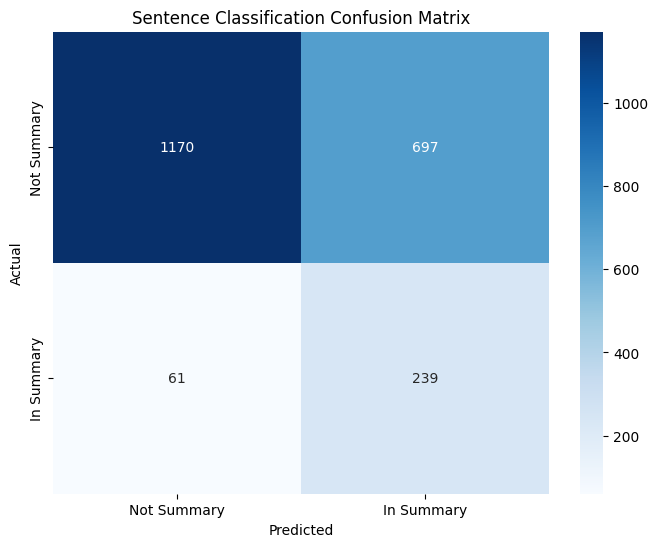

/tmp/ipykernel_4216/1221807407.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([scores['rouge1'], scores['rouge2'], scores['rougeL']],


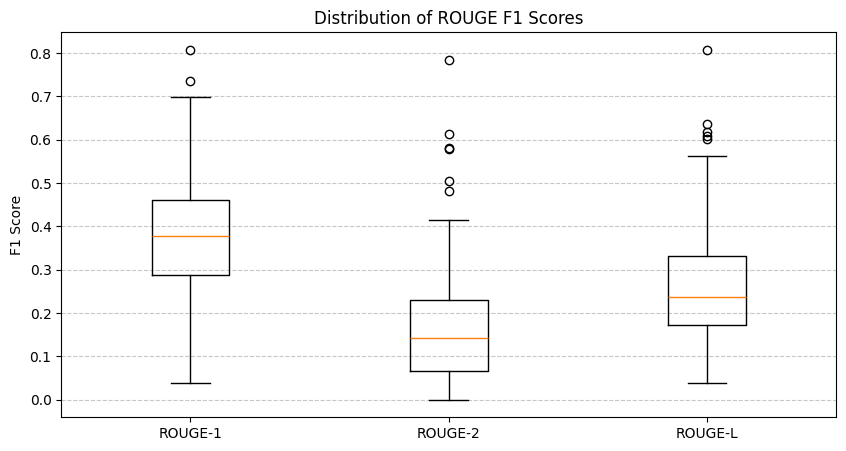

In [ ]:
# 1. Confusion Matrix Visualization
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Summary', 'In Summary'],
            yticklabels=['Not Summary', 'In Summary'])
plt.title('Sentence Classification Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# 2. ROUGE Score Distribution
plt.figure(figsize=(10, 5))
plt.boxplot([scores['rouge1'], scores['rouge2'], scores['rougeL']],
            labels=['ROUGE-1', 'ROUGE-2', 'ROUGE-L'])
plt.title('Distribution of ROUGE F1 Scores')
plt.ylabel('F1 Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


## Custom Testing Interface
Use the function below to test the summarizer on any custom news article or text.

In [ ]:
def summarize_custom_text(text):
    """Allows testing the summarizer with custom text input."""
    sents = split_sentences(text)
    if len(sents) < 1:
        return "Text too short."

    ex = {"sentences": sents}
    summary = predict_summary(ex)

    print("--- ORIGINAL TEXT ---")
    print(text[:500] + "..." if len(text) > 500 else text)
    print("\n--- GENERATED SUMMARY (Extractive) ---")
    print(summary)
    return summary

# Example custom article for testing
custom_article = """
Dennis Muilenburg served as the CEO of Boeing during the 737 MAX crisis. He initially defended the aircraft's new safety software, but later acknowledged that it played a role in the fatal crashes. The Maneuvering Characteristics Augmentation System (MCAS) was designed to automatically prevent stalls. However, it repeatedly pushed the nose of the plane down when it received faulty sensor data. Several engineers had previously raised concerns about this single point of failure, but they were largely ignored by management.
"""

_ = summarize_custom_text(custom_article)

Embedding Batches:   0%|          | 0/1 [00:00<?, ?it/s]

--- ORIGINAL TEXT ---

Dennis Muilenburg served as the CEO of Boeing during the 737 MAX crisis. He initially defended the aircraft's new safety software, but later acknowledged that it played a role in the fatal crashes. The Maneuvering Characteristics Augmentation System (MCAS) was designed to automatically prevent stalls. However, it repeatedly pushed the nose of the plane down when it received faulty sensor data. Several engineers had previously raised concerns about this single point of failure, but they were lar...

--- GENERATED SUMMARY (Extractive) ---
Dennis Muilenburg served as the CEO of Boeing during the 737 MAX crisis. He initially defended the aircraft's new safety software, but later acknowledged that it played a role in the fatal crashes. However, it repeatedly pushed the nose of the plane down when it received faulty sensor data.


## 7. The Ultimate Summarization Dashboard
This interactive interface combines ML classification, MMR for diversity, NER for entities, and Coreference Resolution.

In [ ]:
from IPython.display import display, HTML, clear_output
import ipywidgets as widgets
from ipywidgets import IntSlider, FloatSlider, Checkbox, Output, VBox, Textarea
import time

def get_entities(text):
    """Extracts key named entities (Person, Org, Geo-political Entity) using spaCy."""
    doc = nlp(text) # Process text with spaCy
    entities = [(ent.text, ent.label_) for ent in doc.ents if ent.label_ in ['PERSON', 'ORG', 'GPE']] # Filter for PERSON, ORG, GPE entities
    return list(dict.fromkeys(entities))[:5]

def get_keywords_tfidf(text, top_n=5):
    """Extracts top N keywords based on TF-IDF scores."""
    vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2)) # Initialize TF-IDF vectorizer
    try:
        sents = split_sentences(text)
        tfidf_matrix = vectorizer.fit_transform(sents) # Compute TF-IDF matrix
        scores = np.asarray(tfidf_matrix.sum(axis=0)).ravel() # Sum TF-IDF scores for each word
        feature_names = vectorizer.get_feature_names_out()
        return [feature_names[i] for i in scores.argsort()[::-1][:top_n]] # Return top N keywords
    except: return []

def apply_mmr(sentence_embeddings, sentence_scores, top_k=3, lambda_param=0.5):
    """Applies Maximal Marginal Relevance (MMR) for diverse and relevant sentence selection."""
    if len(sentence_scores) == 0: return []
    selected_indices, remaining_indices = [], list(range(len(sentence_scores))) # Initialize indices
    first_idx = np.argmax(sentence_scores)
    selected_indices.append(first_idx)
    remaining_indices.remove(first_idx)
    while len(selected_indices) < min(top_k, len(sentence_scores)): # Iteratively add sentences
        mmr_scores = []
        for idx in remaining_indices:
            relevance = sentence_scores[idx] # Get sentence relevance
            similarities = cosine_similarity([sentence_embeddings[idx]], [sentence_embeddings[i] for i in selected_indices]) # Calculate similarity to selected sentences
            redundancy = np.max(similarities) # Find max similarity (redundancy)
            score = lambda_param * relevance - (1 - lambda_param) * redundancy # Calculate MMR score
            mmr_scores.append((score, idx))
        next_idx = max(mmr_scores, key=lambda x: x[0])[1]
        selected_indices.append(next_idx)
        remaining_indices.remove(next_idx)
    return sorted(selected_indices)

# Dedicated output area for the dashboard
dashboard_out = Output()

def ultimate_summarize(text, top_k=3, lambda_val=0.5, use_coref=False):
    """Main function for the interactive summarization dashboard, integrating various NLP techniques."""
    display_text = text
    if use_coref:
        with dashboard_out:
            clear_output(wait=True)
            print("Running Coreference Resolution... (Please wait)")
        display_text = resolve_coreferences(text) # Conditional coreference resolution

    sents = split_sentences(display_text) # Split text into sentences
    if not sents:
        with dashboard_out:
            clear_output(wait=True)
            print("No sentences found.")
        return

    embeddings = embedder.encode(sents, batch_size=16) # Encode sentences
    num_sents = len(sents)

    vectorizer = TfidfVectorizer(stop_words='english')
    try:
        tfidf_matrix = vectorizer.fit_transform(sents) # Compute TF-IDF scores for sentences
        tfidf_scores = np.asarray(tfidf_matrix.sum(axis=1)).ravel()
    except: tfidf_scores = np.zeros(num_sents)

    extra = [[i/(num_sents-1) if num_sents>1 else 0.0, len(s.split()), tfidf_scores[i]] for i, s in enumerate(sents)] # Prepare position, length, TF-IDF features
    X = np.hstack([embeddings, np.array(extra, dtype=np.float32)]) # Combine features

    probs = clf.predict_proba(X)[:, 1] # Get prediction probabilities
    top_indices = apply_mmr(embeddings, probs, top_k=top_k, lambda_param=lambda_val) # Apply MMR to select sentences

    entities = get_entities(text) # Extract named entities
    keywords = get_keywords_tfidf(text) # Extract keywords

    ent_html = " ".join([f'<span style="background:#ffccbc; color:#bf360c; padding:2px 8px; margin-right:5px; border-radius:15px; font-size:0.85em"><b>{n}</b> ({l})</span>' for n,l in entities])
    key_html = " ".join([f'<span style="background:#e1f5fe; color:#01579b; padding:2px 8px; margin-right:5px; border-radius:15px; font-size:0.85em">#{kw}</span>' for kw in keywords])

    html_output = f"<div style='font-family: sans-serif;'><h4>Key Entities:</h4>{ent_html}<br><h4>Key Themes:</h4>{key_html}<br><br>"
    html_output += f"<p style='font-size: 0.9em; color: #666;'><i>Showing: {'Resolved Text' if use_coref else 'Original Text'}</i></p>"
    html_output += "<div style='line-height:1.7; border:1px solid #ddd; padding:20px; border-radius:12px; background-color:#fcfcfc; color:#333;'>"
    for i, s in enumerate(sents):
        if i in top_indices:
            html_output += f"<mark style='background:#fff176; color:#000; padding:2px 4px; border-radius:3px; font-weight:500;'>{s}</mark> " # Highlight selected sentences
        else:
            html_output += f"<span style='color:#999'>{s}</span> "
    html_output += "</div></div>"

    with dashboard_out:
        clear_output(wait=True)
        display(HTML(html_output))

print("--- ULTIMATE EXTRACTIVE SUMMARIZATION DASHBOARD ---")
# Interactive widgets for dashboard controls
controls = widgets.interactive(ultimate_summarize,
         text=Textarea(value=custom_article, description='Article:', layout=widgets.Layout(width='95%', height='250px')),
         top_k=IntSlider(min=1, max=10, value=3, description='Summary Length (sentences)'),
         lambda_val=FloatSlider(min=0.0, max=1.0, step=0.1, value=0.5, description='MMR Lambda (Relevance vs. Diversity)'),
         use_coref=Checkbox(value=False, description='Enable Coref Resolution'))

# Display dashboard UI
ui_layout = VBox([VBox(controls.children[:-1]), dashboard_out])
display(ui_layout)
controls.update()


--- ULTIMATE EXTRACTIVE SUMMARIZATION DASHBOARD ---


## Lead-3 Baseline Comparison
In news articles, the most important information is often in the first few sentences (the 'inverted pyramid' style). A common baseline is to simply take the first 3 sentences. Let's see how our ML model compares to this simple heuristic.

In [ ]:
def get_lead3_summary(ex, max_words=60):
    """Generates a Lead-3 summary by taking the first 3 sentences."""
    return build_summary(ex['sentences'], [0, 1, 2], max_words=max_words) # Select first 3 sentences

# Store ROUGE scores for the Lead-3 baseline
lead3_scores = {'rouge1': [], 'rouge2': [], 'rougeL': []}

# Calculate ROUGE scores for Lead-3 summaries
for ex in tqdm(test_examples, desc='Calculating Lead-3'):
    pred = get_lead3_summary(ex, cfg.max_summary_words)
    s = scorer.score(ex['reference'], pred)
    lead3_scores['rouge1'].append(s['rouge1'].fmeasure)
    lead3_scores['rouge2'].append(s['rouge2'].fmeasure)
    lead3_scores['rougeL'].append(s['rougeL'].fmeasure)

print('--- Lead-3 Baseline ROUGE F1 ---')
for k in ['rouge1', 'rouge2', 'rougeL']:
    print(f'{k}: {np.mean(lead3_scores[k]):.4f}')

print('\n--- Our Model (Classifier + MMR) ROUGE F1 ---')
for k in ['rouge1', 'rouge2', 'rougeL']:
    print(f'{k}: {np.mean(scores[k]):.4f}')


Calculating Lead-3:   0%|          | 0/100 [00:00<?, ?it/s]

--- Lead-3 Baseline ROUGE F1 ---
rouge1: 0.3840
rouge2: 0.1710
rougeL: 0.2464

--- Our Model (Classifier + MMR) ROUGE F1 ---
rouge1: 0.3846
rouge2: 0.1677
rougeL: 0.2650


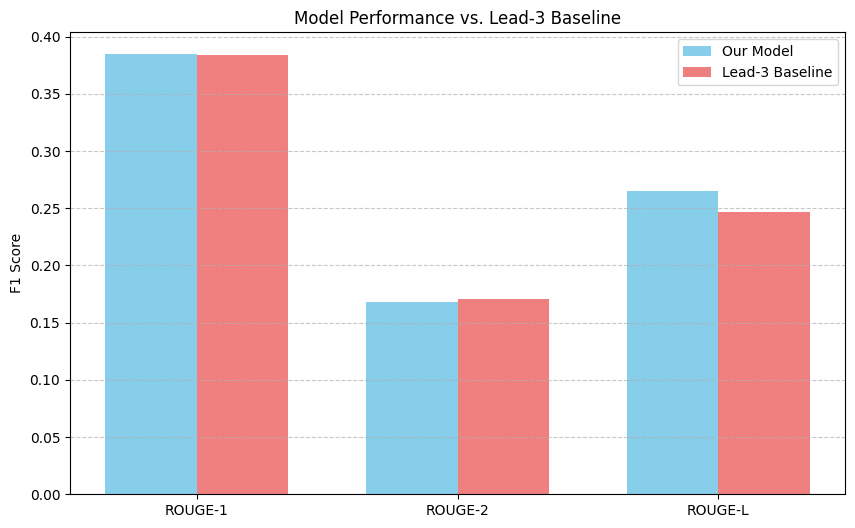

In [ ]:
labels = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L']
model_means = [np.mean(scores['rouge1']), np.mean(scores['rouge2']), np.mean(scores['rougeL'])]
lead3_means = [np.mean(lead3_scores['rouge1']), np.mean(lead3_scores['rouge2']), np.mean(lead3_scores['rougeL'])]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, model_means, width, label='Our Model', color='skyblue')
rects2 = ax.bar(x + width/2, lead3_means, width, label='Lead-3 Baseline', color='lightcoral')

ax.set_ylabel('F1 Score')
ax.set_title('Model Performance vs. Lead-3 Baseline')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Alternative Architecture: MiniLM + XGBoost
In this section, we compare our current pipeline against a more lightweight embedding model and a non-linear gradient-boosted classifier.

In [ ]:
from pathlib import Path
from joblib import dump, load
from xgboost import XGBClassifier

# 1. Initialize MiniLM Embedder (alternative, lightweight model)
minilm_embedder = Embedder("sentence-transformers/all-MiniLM-L6-v2", 128)

def flatten_alt(examples):
    """Flattens examples for MiniLM embeddings and XGBoost (position and length features only)."""
    sents, labels, extra = [], [], []
    for ex in examples: # Process each example
        num_sents = len(ex['sentences'])
        for i in range(num_sents):
            pos = i / (num_sents - 1) if num_sents > 1 else 0.0 # Calculate position feature
            extra.append([pos, len(ex['sentences'][i].split())])
            sents.append(ex['sentences'][i])
            labels.append(ex['labels'][i])

    X_embeds = minilm_embedder.encode(sents, batch_size=32) # Encode sentences using MiniLM
    X = np.hstack([X_embeds, np.array(extra, dtype=np.float32)]) # Combine embeddings and extra features
    return X, np.array(labels)

print("Extracting features for MiniLM + XGBoost...")
X_train_alt, y_train_alt = flatten_alt(train_examples)
X_test_alt, y_test_alt = flatten_alt(test_examples)

models_dir = Path("outputs")
models_dir.mkdir(exist_ok=True)
xgb_path = models_dir / "minilm_xgboost.joblib"

if xgb_path.exists():
    xgb_clf = load(xgb_path)
    print(f"Loaded XGBoost model from {xgb_path}")
else:
    # Calculate scale_pos_weight for class imbalance in XGBoost
    ratio = np.sum(y_train_alt == 0) / np.sum(y_train_alt == 1)

    # 2. Train XGBoost classifier
    xgb_clf = XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=ratio,
        random_state=SEED
    )
    xgb_clf.fit(X_train_alt, y_train_alt)
    dump(xgb_clf, xgb_path)
    print(f"Trained and saved XGBoost model to {xgb_path}")

# 3. Evaluate XGBoost model
y_pred_alt = xgb_clf.predict(X_test_alt)
print(f"Adjusted XGBoost Sentence Accuracy: {accuracy_score(y_test_alt, y_pred_alt):.4f}")
print(classification_report(y_test_alt, y_pred_alt))

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Extracting features for MiniLM + XGBoost...


Embedding Batches:   0%|          | 0/727 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/68 [00:00<?, ?it/s]

Trained and saved XGBoost model to outputs/minilm_xgboost.joblib
Adjusted XGBoost Sentence Accuracy: 0.6996
              precision    recall  f1-score   support

           0       0.94      0.70      0.80      1867
           1       0.27      0.71      0.40       300

    accuracy                           0.70      2167
   macro avg       0.61      0.70      0.60      2167
weighted avg       0.85      0.70      0.74      2167



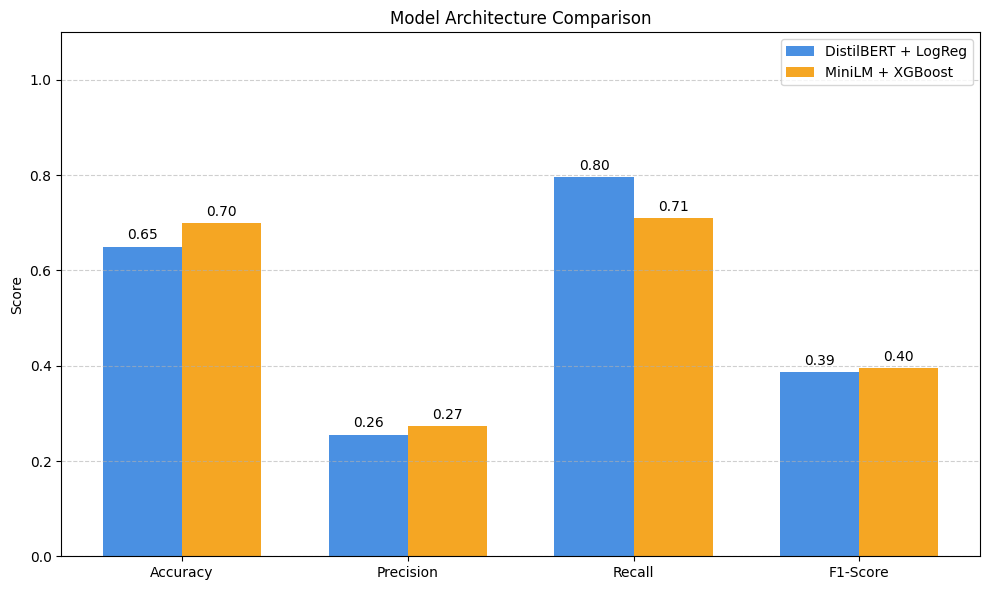

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

# Calculate metrics for DistilBERT + LogReg model
p1, r1, f1_1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary', zero_division=0)
acc1 = accuracy_score(y_test, y_pred)

# Calculate metrics for MiniLM + XGBoost model
p2, r2, f1_2, _ = precision_recall_fscore_support(y_test_alt, y_pred_alt, average='binary', zero_division=0)
acc2 = accuracy_score(y_test_alt, y_pred_alt)

metrics_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
model1_vals = [acc1, p1, r1, f1_1]
model2_vals = [acc2, p2, r2, f1_2]

x = np.arange(len(metrics_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, model1_vals, width, label='DistilBERT + LogReg', color='#4A90E2')
rects2 = ax.bar(x + width/2, model2_vals, width, label='MiniLM + XGBoost', color='#F5A623')

ax.set_ylabel('Score')
ax.set_title('Model Architecture Comparison')
ax.set_xticks(x)
ax.set_xticklabels(metrics_labels)
ax.legend()

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 8. Benchmarking Alternative Architectures
Comparing the DistilBERT + Logistic Regression approach with a MiniLM + XGBoost pipeline.

In [ ]:
from IPython.display import display, HTML

def predict_summary_xgb(ex):
    """Predicts an extractive summary using MiniLM + XGBoost model."""
    num_sents = len(ex['sentences'])
    embeddings = minilm_embedder.encode(ex['sentences'], batch_size=32) # Get MiniLM embeddings

    extra = []
    for i in range(num_sents):
        pos = i / (num_sents - 1) if num_sents > 1 else 0.0 # Calculate position feature
        extra.append([pos, len(ex['sentences'][i].split())])

    X = np.hstack([embeddings, np.array(extra, dtype=np.float32)]) # Combine features
    probs = xgb_clf.predict_proba(X)[:, 1] # Get prediction probabilities from XGBoost
    top_idx = apply_mmr(embeddings, probs, top_k=cfg.oracle_top_k, lambda_param=0.5) # Apply MMR
    return build_summary(ex['sentences'], top_idx, cfg.max_summary_words)

# Select a random test example for comparison
sample_idx = np.random.randint(0, len(test_examples))
test_ex = test_examples[sample_idx]

# Get summaries from both models
summary_orig = predict_summary(test_ex)
summary_xgb = predict_summary_xgb(test_ex)

# Generate HTML to display comparison
html_content = f"""
<div style='font-family: -apple-system, system-ui, sans-serif; border: 1px solid #e1e4e8; border-radius: 10px; overflow: hidden; box-shadow: 0 4px 12px rgba(0,0,0,0.05);'>
    <div style='background-color: #24292e; padding: 16px; color: #ffffff;'>
        <h3 style='margin: 0; font-size: 16px; font-weight: 600;'>Summarization Benchmarking</h3>
        <p style='color: #959da5; margin: 4px 0 0 0; font-size: 13px;'>Comparing DistilBERT vs. MiniLM Architecture</p>
    </div>
    <div style='padding: 16px; background-color: #f6f8fa; border-bottom: 1px solid #e1e4e8;'>
        <span style='font-size: 11px; text-transform: uppercase; letter-spacing: 0.05em; color: #586069; font-weight: bold;'>Ground Truth Reference</span>
        <p style='margin: 8px 0 0 0; font-size: 14px; line-height: 1.6; color: #24292e;'>{test_ex['reference']}</p>
    </div>
    <div style='display: flex; flex-wrap: wrap; background: #ffffff;'>
        <div style='flex: 1; min-width: 300px; padding: 20px; border-right: 1px solid #e1e4e8;'>
            <div style='margin-bottom: 12px;'>
                <span style='background: #e1e4e8; color: #24292e; padding: 4px 10px; border-radius: 4px; font-size: 12px; font-weight: 600;'>DistilBERT + LogReg</span>
            </div>
            <p style='margin: 0; font-size: 14px; line-height: 1.7; color: #444;'>{summary_orig}</p>
        </div>
        <div style='flex: 1; min-width: 300px; padding: 20px;'>
            <div style='margin-bottom: 12px;'>
                <span style='background: #0366d6; color: #ffffff; padding: 4px 10px; border-radius: 4px; font-size: 12px; font-weight: 600;'>MiniLM + XGBoost</span>
            </div>
            <p style='margin: 0; font-size: 14px; line-height: 1.7; color: #444;'>{summary_xgb}</p>
        </div>
    </div>
</div>
"""

display(HTML(html_content))


Embedding Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Embedding Batches:   0%|          | 0/1 [00:00<?, ?it/s]

## 9. Save Models

In [ ]:
from pathlib import Path
from joblib import dump

models_dir = Path("outputs")
models_dir.mkdir(exist_ok=True)

for model_name, filename in [("clf", "distilbert_logreg.joblib"), ("xgb_clf", "minilm_xgboost.joblib")]:
    if model_name in globals():
        model = globals()[model_name]
        model_to_save = getattr(model, "_model", model)
        dump(model_to_save, models_dir / filename)
        print(f"Saved {model_name} to {models_dir / filename}")
    else:
        print(f"{model_name} is not available in memory, so nothing was saved.")

Saved clf to outputs/distilbert_logreg.joblib
Saved xgb_clf to outputs/minilm_xgboost.joblib
